# News coverage: definitions and descriptive findings

This notebook explains the dashboard, reproduces selected results and evaluates the proposed two-sided coverage index in Erik's draft. It uses **existing public aggregates**, not fresh model output. The storage audit is **November 4, 2026, 13:38:01 UTC**. Article period: **January 2022–May 2026**, unless a cell explicitly selects 2024.

Each observation is an article with one selected action and an evaluated national incumbent government. `align` describes support/opposition by the action, `rep` describes implications for the government's reputation, and `frame` describes explicit evaluation in the title/narrator. They are different constructs. Zero is a substantive coding outcome; null means not codable. These descriptive statistics do not establish accuracy, public attitudes or causal effects.

Read the [dashboard guide](../docs/dashboard-guide.md), [codebook](../docs/codebook.md), [data card](../docs/data-card.md) and [validation documentation](../docs/validation.md) alongside the results. Figure captions state their scope and interpretation. All figures are exported to `figures/` as PNG and PDF.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / "scripts/analysis_utils.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "scripts/analysis_utils.py").exists(), "Run from the repository or notebooks directory"
sys.path.insert(0, str(ROOT / "scripts"))
from analysis_utils import load, marginal, measures, correlation, radius, AXES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
TABLES = ROOT / "data/analysis"; TABLES.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / (name + ".png"), dpi=180, bbox_inches="tight")
    fig.savefig(FIG / (name + ".pdf"), bbox_inches="tight")
    plt.show()
D = load("explore-post2021.json")
META = load("explore-meta.json")
CTX = load("country_context.json")
MONTHLY = load("explore-monthly.json")
assert sum(D["overall"]["c"]) == D["quality"]["complete"] == 1984402
assert META["prompt_sha256"] == json.loads((ROOT / "data/analysis_snapshot.json").read_text())["prompt_sha256"]
scope = pd.DataFrame([{"Period": D["label"], "Valid": D["quality"]["valid"], "Eligible": D["quality"]["complete"]}])
display(scope)


,Period,Valid,Eligible
0,Jan 2022–May 2026,2157912,1984402


## Denominators and the three distributions

The default comparison requires an identified government and primary action and all three labels codable as −1, 0, +1. The difference between valid and eligible is not one political category. Missing-axis and missing-group counts overlap and must not be added as independent exclusions. An actor/target subgroup can have a smaller denominator; the similarity cloud is stricter still.

The old October 29 repository tables describe 542,981 valid records from January 2025–May 2026, retaining null in each marginal percentage denominator. They remain as a historical snapshot and must not be silently combined with this common eligible sample.

,n,negative,zero,positive,net,two_sided
measure,,,,,,
align,1984402,0.0984,0.8216,0.0800,-0.0184,0.0315
rep,1984402,0.1067,0.8586,0.0347,-0.0720,0.0148
frame,1984402,0.0526,0.9212,0.0262,-0.0264,0.0055


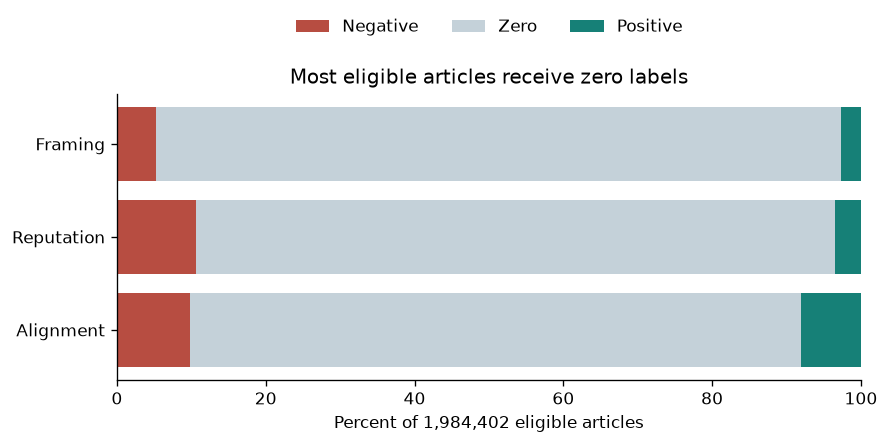

In [2]:
summary = pd.DataFrame([{"measure": a, **measures(D["overall"], a)} for a in AXES]).set_index("measure")
summary.to_csv(TABLES / "overall_measures.csv")
display(summary.round(4))
fig, ax = plt.subplots(figsize=(8, 3.1))
left = np.zeros(3)
for field, color in zip(["negative", "zero", "positive"], ["#b74d41", "#c4d1d9", "#168077"]):
    ax.barh(["Alignment", "Reputation", "Framing"], 100*summary[field], left=left, color=color, label=field.title())
    left += 100*summary[field].to_numpy()
ax.set(xlabel="Percent of 1,984,402 eligible articles", xlim=(0, 100), title="Most eligible articles receive zero labels")
ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.15), ncol=3, frameon=False)
save(fig, "01_label_distributions")

**Figure 1.** Three label distributions on the same eligible records, January 2022–May 2026. Zero includes neutral, mixed and insufficient directional evidence. It does not establish unbiased coverage. The common denominator enables comparison but excludes uncodable records.

## Alignment and reputation: the relationship changes by actor

The correlation treats −1, 0, +1 as equally spaced numeric values. It is an article-level descriptive association. It is not a correlation between the government means in the cloud and does not prove that supportive actions improve reputation. The conditional percentage below asks how often supportive actions have unfavorable reputational implications.

All eligible: correlation                               0.335501
Executive/cabinet: correlation                         -0.007742
Unfavorable reputation among supportive actions         0.194722
Executive/cabinet eligible n                       271068.000000
dtype: float64

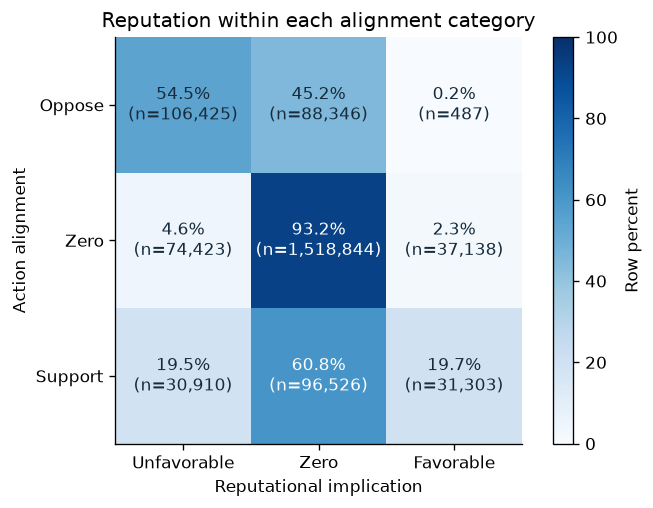

In [3]:
executive = next(row for row in D["groups"]["actor_role"] if row["k"] == "A")
joint = np.array(D["overall"]["c"]).reshape(3,3,3).sum(axis=2)
findings = pd.Series({"All eligible: correlation": correlation(D["overall"]),
                      "Executive/cabinet: correlation": correlation(executive),
                      "Unfavorable reputation among supportive actions": joint[2,0]/joint[2,:].sum(),
                      "Executive/cabinet eligible n": sum(executive["c"])})
assert abs(findings.iloc[0] - .336) < .002
assert abs(findings.iloc[1] - (-.008)) < .002
display(findings)
pd.DataFrame(joint, index=["Oppose", "Zero", "Support"], columns=["Unfavorable", "Zero", "Favorable"]).to_csv(TABLES / "alignment_reputation_counts.csv")
fig, ax = plt.subplots(figsize=(6.7, 4.4))
percent = 100*joint/joint.sum(axis=1, keepdims=True)
im=ax.imshow(percent, cmap="Blues", vmin=0, vmax=100)
for i in range(3):
    for j in range(3):
        ax.text(j,i,f"{percent[i,j]:.1f}%\n(n={joint[i,j]:,})", ha="center",va="center",color="white" if percent[i,j]>60 else "#172b3b")
ax.set(xticks=range(3), xticklabels=["Unfavorable", "Zero", "Favorable"], yticks=range(3), yticklabels=["Oppose", "Zero", "Support"], xlabel="Reputational implication", ylabel="Action alignment", title="Reputation within each alignment category")
fig.colorbar(im, ax=ax, label="Row percent")
save(fig, "02_alignment_reputation")

**Figure 2.** Row percentages use all eligible articles within each alignment category; counts show the unequal row denominators. The pooled correlation is about 0.336, but approximately −0.008 for executive/cabinet actors. About 19.5% of supportive actions are unfavorable for reputation. Actor and action composition are plausible explanations to investigate, not established causes of the correlation difference.

## Article period, country year and point size

**Article period filters news. External indicator year selects country statistics.** They are independent because a common institutional snapshot and a multi-year article profile answer a different question from a contemporaneous country-year comparison. To align them, set both to 2024. There are no observed 2026 V-Dem scores in this release; 2025 is an explicitly labeled reference for that year.

Government context refers to the evaluated country; outlet context refers to publication country. Regions are static and need no year. Direct label axes use mean/net or a selected share. Institutional axes use the selected external indicator; label colors always use means. The dashboard now hides the external-year control when the current plot does not use it.

Point size counts eligible articles, not population, readership, independent events or uncertainty. Dashboard radius is `4 + min(12, sqrt(n)/30)` in SVG coordinates; it caps at 129,600. **Circle area is not proportional to count.** Equal size sets radius to 6. Exact counts are available on hover/click and in the point list. The figure below uses the same compressed radius rule, in plotting units.

,Eligible articles,Dashboard radius
0,500,4.745356
1,5000,6.357023
2,50000,11.453560
3,129600,16.000000
4,300000,16.000000


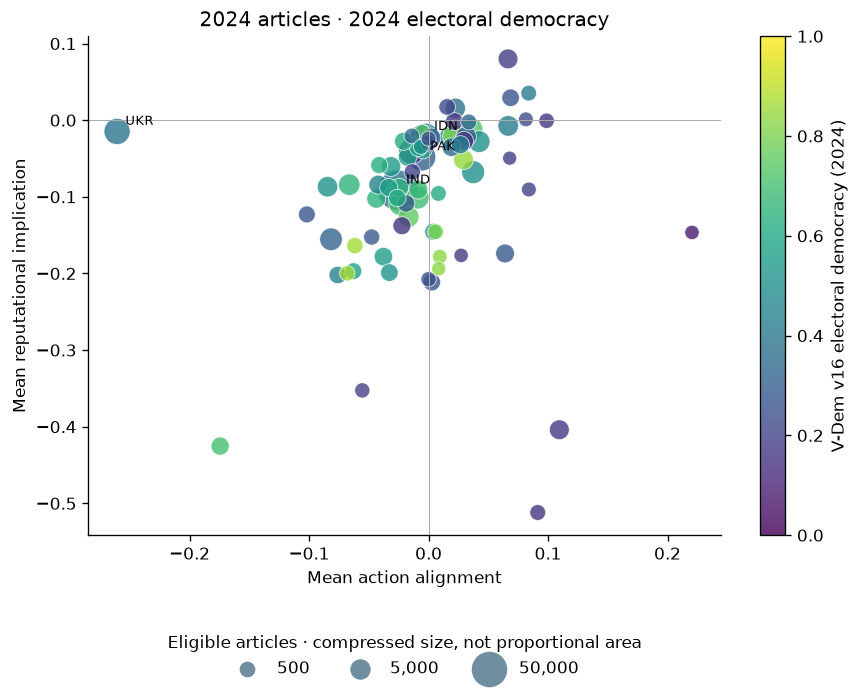

78 governments shown, at least 500 eligible articles and an available 2024 score.


In [4]:
display(pd.DataFrame({"Eligible articles": [500,5000,50000,129600,300000], "Dashboard radius": [radius(n) for n in [500,5000,50000,129600,300000]]}))
D24 = load("explore-2024.json")
rows=[]
for row in D24["groups"]["gov"]:
    n=sum(row["c"]); context=CTX["country_year"].get(row["k"]+"_2024", {})
    if n>=500 and context.get("v2x_polyarchy") is not None:
        rows.append({"government":row["k"],"n":n,"mean_align":measures(row,"align")["net"],"mean_rep":measures(row,"rep")["net"],"democracy_2024":context["v2x_polyarchy"]})
cloud=pd.DataFrame(rows)
cloud.to_csv(TABLES / "government_cloud_2024.csv", index=False)
fig,ax=plt.subplots(figsize=(8.5,5.4))
points=ax.scatter(cloud.mean_align,cloud.mean_rep,s=[np.pi*radius(n)**2 for n in cloud.n],c=cloud.democracy_2024,cmap="viridis",vmin=0,vmax=1,alpha=.8,edgecolor="white",linewidth=.5)
for row in cloud.nlargest(4,"n").itertuples():
    ax.annotate(row.government,(row.mean_align,row.mean_rep),xytext=(5,4),textcoords="offset points",fontsize=8)
ax.axhline(0,color="#aaa",lw=.6);ax.axvline(0,color="#aaa",lw=.6)
ax.set(xlabel="Mean action alignment",ylabel="Mean reputational implication",title="2024 articles · 2024 electoral democracy")
fig.colorbar(points,ax=ax,label="V-Dem v16 electoral democracy (2024)")
handles=[ax.scatter([],[],s=np.pi*radius(n)**2,color="#708e9f",label=f"{n:,}") for n in [500,5000,50000]]
ax.legend(handles=handles,title="Eligible articles · compressed size, not proportional area",loc="upper center",bbox_to_anchor=(.5,-.17),ncol=3,frameon=False)
save(fig, "03_government_cloud_2024")
print(f"{len(cloud)} governments shown, at least 500 eligible articles and an available 2024 score.")

**Figure 3.** Each point is an evaluated-government country, with both article period and institutional year set to 2024. Four highest-volume points are labeled by country code. Missing institutional observations and small groups are omitted. Country means are article-weighted within each group. An institutional color does not establish an institutional effect; source composition and measurement error remain unresolved. Source: Coppedge et al. (2026), V-Dem Country-Date Dataset v16, https://doi.org/10.23696/vdemds26; values/adaptations CC BY-SA 4.0. The downloaded context manifest retains exact source hashes.

The dashboard's **similarity** mode differs from this direct comparison: it uses known actors and classified actions, transforms five distributions with equal field weights and projects them to two principal components. Clusters are fitted to the full profiles. Display filtering does not refit them. Their sample counts can be lower and their axes are not ideological scales.

## Monthly change, contributions and a documented story

For each country-month, all three measures use the same eligible records. A spike compares the current month with the **pooled previous three calendar months**. The following example is descriptive: Senegal's February 2024 election postponement and court reversal supply relevant external context. Those sources have not been matched to the corpus article by article, so the plot does not estimate event-specific coverage or causal impact.

,Measure,Pooled baseline n,Current n,Baseline negative %,Current negative %,Change pp
0,align,646,934,10.53,19.49,8.96
1,rep,646,934,5.73,31.37,25.64
2,frame,646,934,2.79,17.02,14.24


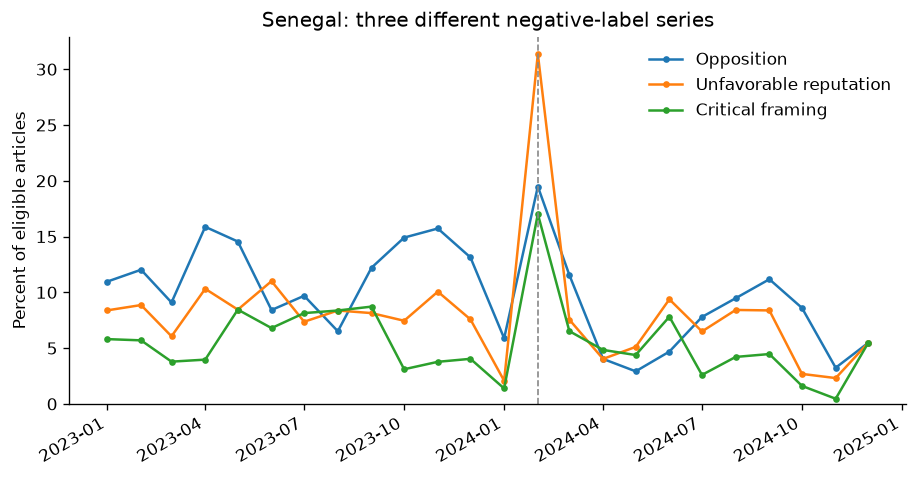

The election scheduled for February was postponed, followed by protests. The Constitutional Council overturned the postponement on 15 February.

Source: [UN Secretary-General report S/2024/521, paragraph 18](https://documents.un.org/doc/undoc/gen/n24/173/40/pdf/n2417340.pdf)

In [5]:
sen=[r for r in MONTHLY["groups"]["gov"] if r["k"]=="SEN" and "2023-01"<=r["month"]<="2024-12"]
sen=sorted(sen,key=lambda r:r["month"])
monthly=pd.DataFrame([{"month":r["month"],"n":sum(r["c"]),**{a:100*measures(r,a)["negative"] for a in AXES}} for r in sen])
monthly.to_csv(TABLES / "senegal_monthly_negative_shares.csv",index=False)
event=next(r for r in sen if r["month"]=="2024-02")
base_rows=[r for r in sen if r["month"] in ["2023-11","2023-12","2024-01"]]
assert len(base_rows)==3
base={"c":np.sum([r["c"] for r in base_rows],axis=0).tolist()}
display(pd.DataFrame([{"Measure":a,"Pooled baseline n":sum(base["c"]),"Current n":sum(event["c"]),"Baseline negative %":100*measures(base,a)["negative"],"Current negative %":100*measures(event,a)["negative"],"Change pp":100*(measures(event,a)["negative"]-measures(base,a)["negative"])} for a in AXES]).round(2))
fig,ax=plt.subplots(figsize=(9,4.5))
dates=pd.to_datetime(monthly.month)
for a,label in zip(AXES,["Opposition", "Unfavorable reputation", "Critical framing"]):
    ax.plot(dates,monthly[a],marker="o",ms=3,label=label)
ax.axvline(pd.Timestamp("2024-02-01"),color="#888",lw=1,ls="--")
ax.set(ylabel="Percent of eligible articles",title="Senegal: three different negative-label series",ylim=(0,None))
ax.legend(frameon=False);fig.autofmt_xdate()
save(fig,"04_senegal_monthly")
event_source=next(e for e in META["events"] if e["gov"]=="SEN" and e["month"]=="2024-02")
display(Markdown(event_source["text"] + "\n\nSource: [" + event_source["source"] + "](" + event_source["url"] + ")"))

**Figure 4.** Senegal, January 2023–December 2024, article-weighted shares. The unfavorable-reputation share rises from about 5.7% in the pooled November–January baseline to 31.4% in February. The dashboard also reports a same-outlet check; that equal-outlet calculation is distinct from this pooled curve. The selected case is a lead for investigation, not a representative estimate of event effects. Sources for the election postponement, protests and Constitutional Council reversal are linked in the displayed event record and dashboard story.

Contributor checkboxes in the dashboard allocate the monthly numerator to action types or actor roles, using the same overall eligible denominator. For example, a specific action's negative contribution is its negative-coded count divided by all eligible group-month articles. Change subtracts the analogous baseline contribution. “Other”, unidentified and unmapped categories are not offered as substantive findings, but their counts remain in the denominator and are disclosed. Actions and actors are separate partitions; adding their contributions would double-count. Named participants appear in sourced story cards; coded role counts are not a resolved person-level network.

## The proposed two-sided coverage index

Erik's draft proposes **P = 4 p⁺ p⁻**. Algebraically, P = (1 − p⁰)² − (p⁺ − p⁻)². This combines directional coverage volume with balance between directions. The index is bounded by 0 and 1. It is zero if either directional side is absent. It is not the same as net direction or negative share.

The following synthetic cases are definitions, not observed data. The notebook subsequently applies the formula separately to each measure. Its relation to established polarization indices and validity for political inference still require evaluation; no link to public attitudes is assumed.

,case,negative,zero,positive,net,P
0,All zero,0.0,1.0,0.0,0.0,0.00
1,All positive,0.0,0.0,1.0,1.0,0.00
2,Balanced directional,0.5,0.0,0.5,0.0,1.00
3,"Balanced, mostly zero",0.1,0.8,0.1,0.0,0.04


,government,month,measure,n,negative,zero,positive,net,two_sided
1443,SEN,2024-02,align,934,0.1949,0.6638,0.1413,-0.0535,0.1102
1444,SEN,2024-02,rep,934,0.3137,0.6734,0.0128,-0.3009,0.0161
1445,SEN,2024-02,frame,934,0.1702,0.8094,0.0203,-0.1499,0.0139


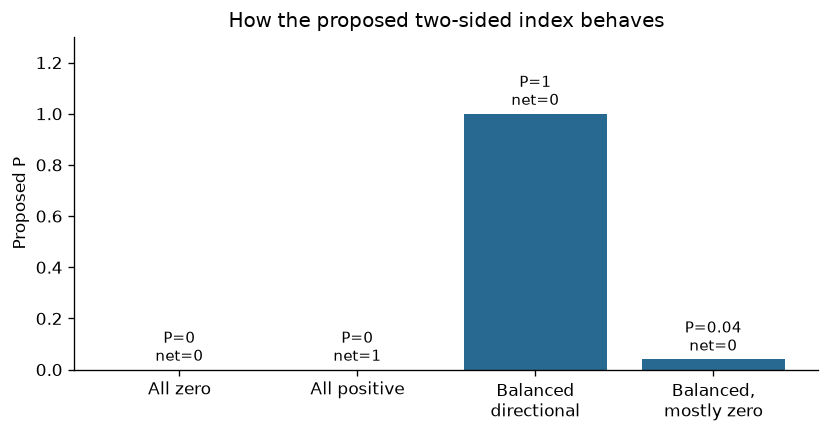

In [6]:
examples=pd.DataFrame({"case":["All zero", "All positive", "Balanced directional", "Balanced, mostly zero"],"negative":[0,0,.5,.1],"zero":[1,0,0,.8],"positive":[0,1,.5,.1]})
examples["net"]=examples.positive-examples.negative
examples["P"]=4*examples.positive*examples.negative
assert np.allclose(examples.P,(1-examples.zero)**2-examples.net**2)
display(examples)
index_rows=[]
for r in MONTHLY["groups"]["gov"]:
    if D["start"]<=r["month"]<=D["end"]:
        for a in AXES:
            index_rows.append({"government":r["k"],"month":r["month"],"measure":a,**measures(r,a)})
indices=pd.DataFrame(index_rows)
assert indices.two_sided.between(0,1).all()
assert np.allclose(indices.two_sided,(1-indices.zero)**2-indices.net**2)
indices.to_csv(TABLES / "government_month_coverage_balance.csv",index=False)
display(indices[(indices.government=="SEN") & (indices.month=="2024-02")].round(4))
fig,ax=plt.subplots(figsize=(8,3.6))
ax.bar(examples.case,examples.P,color="#276990")
ax.set(ylim=(0,1.3),ylabel="Proposed P",title="How the proposed two-sided index behaves")
for i,row in examples.iterrows(): ax.text(i,row.P+.035,f"P={row.P:g}\nnet={row.net:g}",ha="center",fontsize=9)
ax.set_xticks(range(4), ["All zero", "All positive", "Balanced\ndirectional", "Balanced,\nmostly zero"])
save(fig,"05_coverage_balance_examples")

**Figure 5.** Synthetic distributions illustrate the candidate measure. All-zero and all-positive cases both have P = 0. A balanced distribution with 80% zero labels has P = 0.04, compared with 1 for equal positive and negative shares without zeros. Always report the three shares, net, P and n together. The country-month output table provides these quantities; it is an exploratory calculation, not a validated polarization series.

## What the evidence supports next

The current evidence supports descriptions of label co-occurrence, role/action differences, country/outlet profiles and selected monthly changes. It does not yet supply a human-validated index, article-matched event comparisons, standardized named-actor networks, or causal lag/lead estimates against democracy.

Priorities are independent human validation on the exact input, translation checks, historically correct government references, stable outlet panels and event-level review of selected spikes. Compare within- and between-outlet variation before interpreting aggregate balance as polarization. Separate annual democracy analysis from fixed-year cloud coloring, and account for incumbent transitions.

The notebook preserves Erik's source deck and identifies supporting materials in [slides/README.md](../slides/README.md). A broad collection count is not the denominator for these figures. Re-run this notebook only against the recorded snapshot; refreshing the analysis cohort requires a new manifest and documented comparison.